# Loan Prediction Analysis - Classification

# Algorithms: Logistic Regression, Decision Tree, Random Forest, Extra Trees

# 1. Imports

In [17]:
import os
import glob
import warnings
 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
 
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42

# 2. Load data

In [20]:
paths = glob.glob("/kaggle/input/**/*.csv", recursive=True) + glob.glob("*.csv")
paths = [p for p in paths if "test" not in os.path.basename(p).lower()]  # skip unlabeled test file
 
if not paths:
    raise FileNotFoundError("No CSV found. On Kaggle click 'Add Input' and add the "
                            "'Loan Prediction Problem Dataset' (altruistdelhite04).")
 
CSV_PATH = paths[0]
df = pd.read_csv(CSV_PATH)
print(f"Loaded {CSV_PATH}: {df.shape}")
assert "Loan_Status" in df.columns, "This file has no Loan_Status column - pick the training CSV."
df.head()

Loaded /kaggle/input/datasets/nayushman/loan-dta-set/train_u6lujuX_CVtuZ9i.csv: (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


# 3. Basic info

In [22]:
df.info()
print("\nMissing values:\n", df.isnull().sum())
print("\nTarget distribution:\n", df["Loan_Status"].value_counts(normalize=True).round(3))
df.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB

Missing values:
 Loan_ID               0
Gender               13
Married               3
Dependents           1

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


# 4. EDA - categorical features vs target


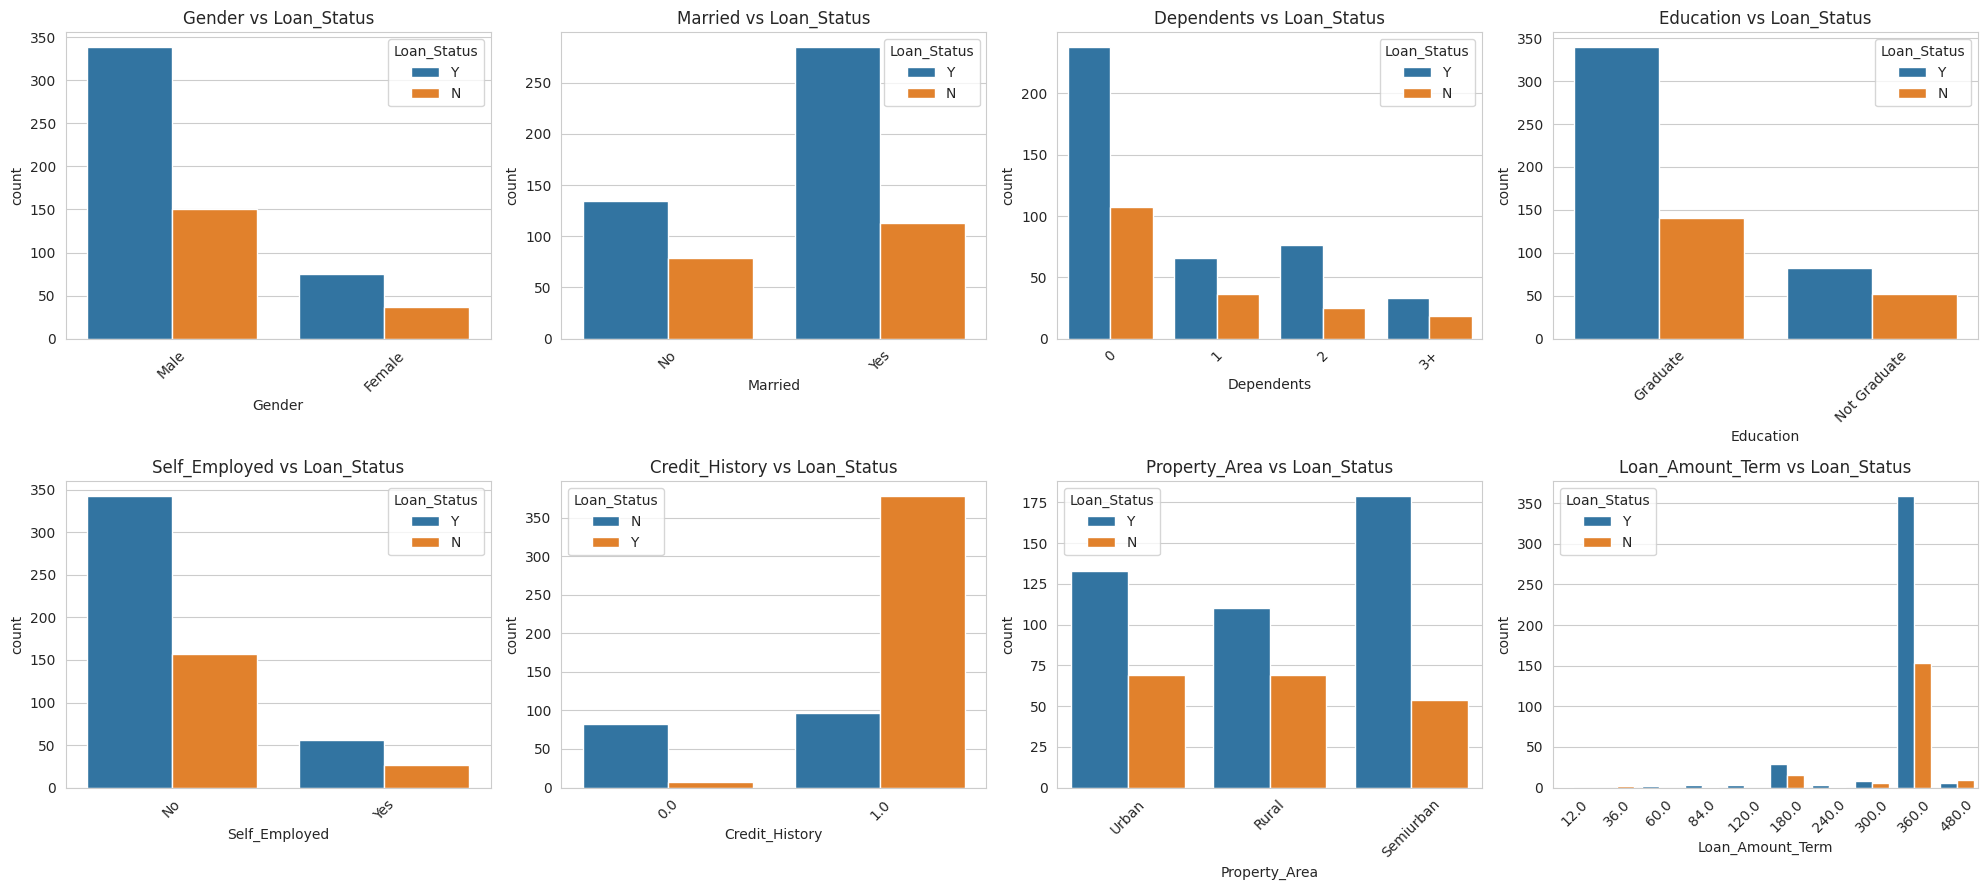

In [23]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
cat_eda = ["Gender", "Married", "Dependents", "Education",
           "Self_Employed", "Credit_History", "Property_Area", "Loan_Amount_Term"]
for ax, col in zip(axes.ravel(), cat_eda):
    sns.countplot(data=df, x=col, hue="Loan_Status", ax=ax)
    ax.set_title(f"{col} vs Loan_Status")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

# 5. EDA - numeric distributions and outliers

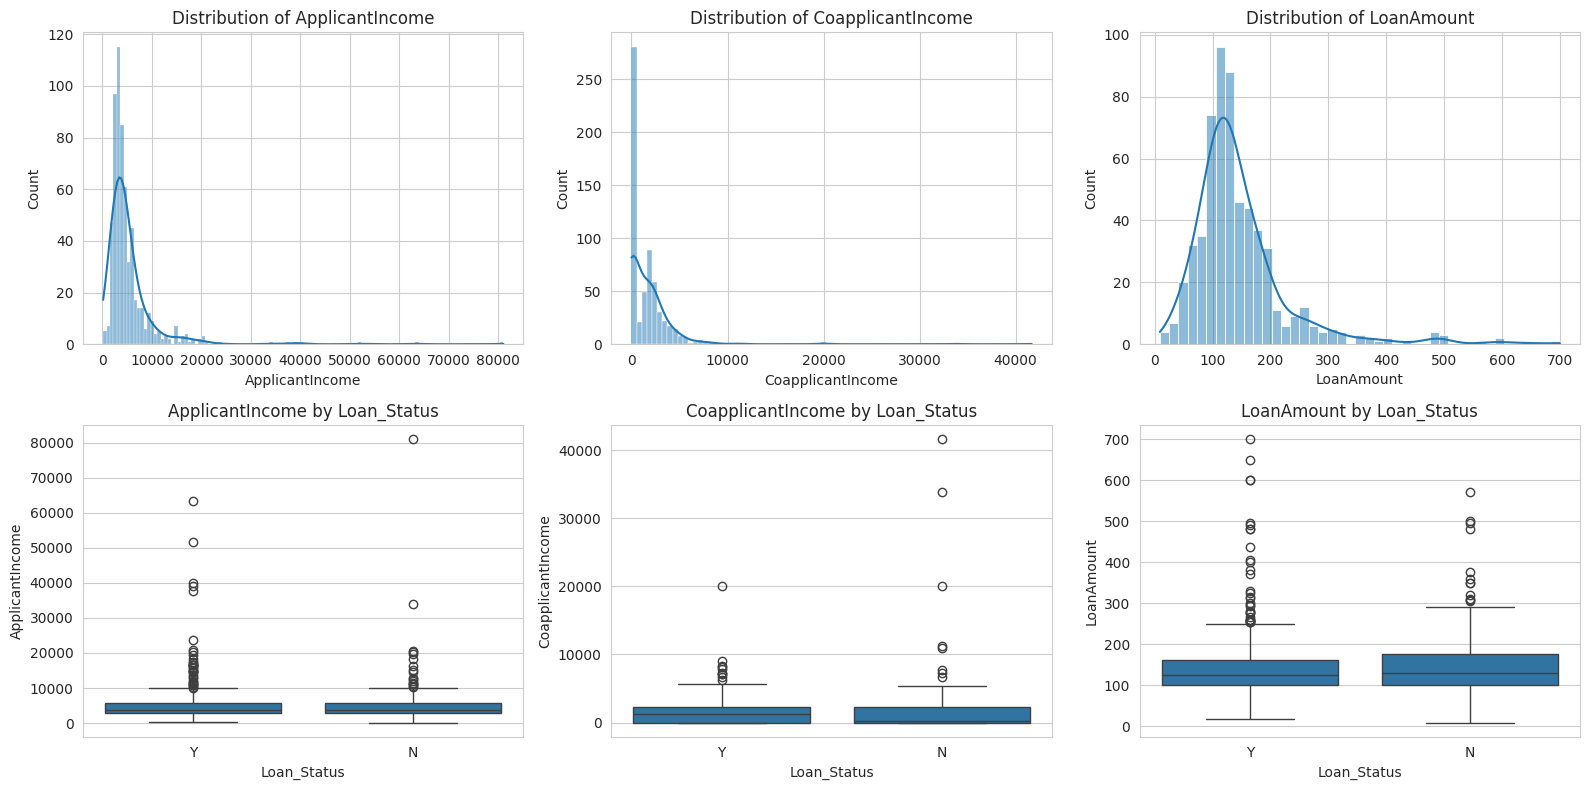

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, col in enumerate(["ApplicantIncome", "CoapplicantIncome", "LoanAmount"]):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[0, i])
    axes[0, i].set_title(f"Distribution of {col}")
    sns.boxplot(x="Loan_Status", y=col, data=df, ax=axes[1, i])
    axes[1, i].set_title(f"{col} by Loan_Status")
plt.tight_layout()
plt.show()

# 6. Feature engineering

In [26]:
data = df.drop(columns=["Loan_ID"]).copy()
data["Dependents"] = pd.to_numeric(data["Dependents"].replace("3+", "3"), errors="coerce")
 
data["TotalIncome"] = data["ApplicantIncome"] + data["CoapplicantIncome"]
data["TotalIncome_log"] = np.log1p(data["TotalIncome"])
data["LoanAmount_log"] = np.log1p(data["LoanAmount"])          # NaN stays NaN, imputed later
data["EMI"] = data["LoanAmount"] / data["Loan_Amount_Term"]    # loan in thousands / months
data["Balance_Income"] = data["TotalIncome"] - data["EMI"] * 1000
 
data = data.drop(columns=["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "TotalIncome"])
 
y = (data.pop("Loan_Status") == "Y").astype(int)
X = data

# Correlation heatmap

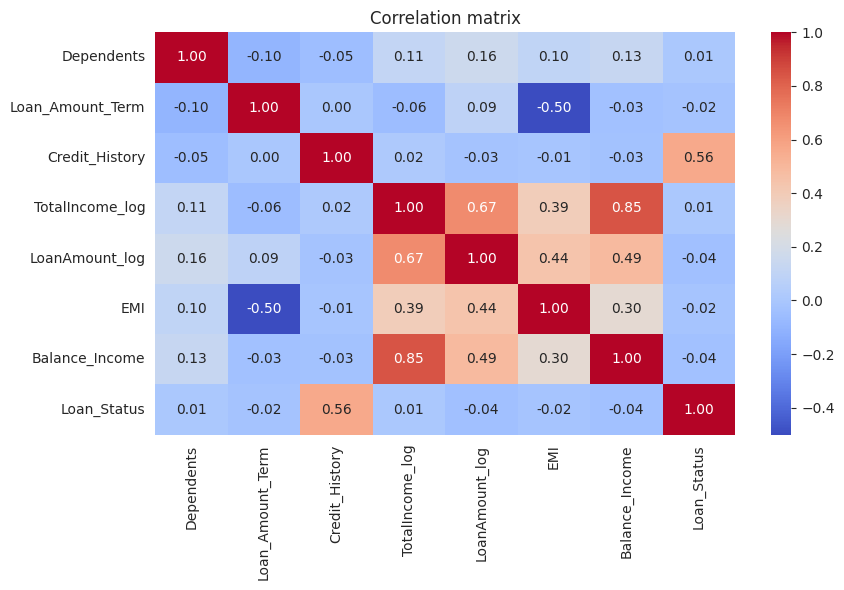

In [27]:
plt.figure(figsize=(9, 6))
sns.heatmap(X.select_dtypes("number").assign(Loan_Status=y).corr(),
            annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

# 7. Preprocessing pipeline (imputation + scaling + encoding inside -> no leakage)

In [35]:
num_cols = ["Dependents", "Loan_Amount_Term", "TotalIncome_log",
            "LoanAmount_log", "EMI", "Balance_Income"]
bin_cols = ["Credit_History"]                                   # already 0/1
cat_cols = ["Gender", "Married", "Education", "Self_Employed", "Property_Area"]
 
preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_cols),
    ("bin", SimpleImputer(strategy="most_frequent"), bin_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])
 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (491, 12)  Test: (123, 12)


# 8. Models + hyperparameter grids

In [36]:
models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        {"clf__C": [0.01, 0.1, 1, 10]}),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"clf__max_depth": [2, 3, 4, 5, 7], "clf__min_samples_leaf": [1, 5, 10, 20]}),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE),
        {"clf__n_estimators": [100, 300], "clf__max_depth": [3, 5, 7, None],
         "clf__min_samples_leaf": [1, 5, 10]}),
    "Extra Trees": (
        ExtraTreesClassifier(random_state=RANDOM_STATE),
        {"clf__n_estimators": [100, 300], "clf__max_depth": [3, 5, 7, None],
         "clf__min_samples_leaf": [1, 5, 10]}),
}

# 9. Train, tune and evaluate

In [37]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results, fitted = [], {}
 
for name, (clf, grid) in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)])
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="accuracy", n_jobs=-1)
    gs.fit(X_train, y_train)
    pred = gs.predict(X_test)
    acc = accuracy_score(y_test, pred)
    fitted[name] = (gs, pred)
    results.append({"Model": name,
                    "CV Accuracy": gs.best_score_ * 100,
                    "Test Accuracy": acc * 100})
    print(f"{name:20s} CV={gs.best_score_*100:.2f}  Test={acc*100:.2f}  params={gs.best_params_}")
 
res_df = pd.DataFrame(results).sort_values("Test Accuracy", ascending=False).reset_index(drop=True)
print("\n=== Model comparison ===")
print(res_df.round(2).to_string(index=False))

Logistic Regression  CV=79.42  Test=85.37  params={'clf__C': 1}
Decision Tree        CV=79.83  Test=85.37  params={'clf__max_depth': 2, 'clf__min_samples_leaf': 20}
Random Forest        CV=79.83  Test=83.74  params={'clf__max_depth': 3, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 100}
Extra Trees          CV=79.83  Test=85.37  params={'clf__max_depth': 3, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 100}

=== Model comparison ===
              Model  CV Accuracy  Test Accuracy
Logistic Regression        79.42          85.37
      Decision Tree        79.83          85.37
        Extra Trees        79.83          85.37
      Random Forest        79.83          83.74


# 10. Model comparison chart

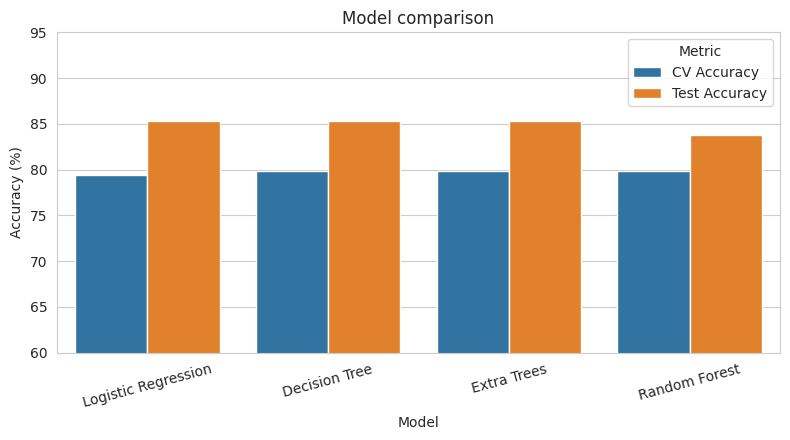

In [39]:
plt.figure(figsize=(8, 4.5))
sns.barplot(data=res_df.melt(id_vars="Model", var_name="Metric", value_name="Accuracy (%)"),
            x="Model", y="Accuracy (%)", hue="Metric")
plt.ylim(60, 95)
plt.xticks(rotation=15)
plt.title("Model comparison")
plt.tight_layout()
plt.show()

# 11. Best model - report and confusion matrix

Best model: Logistic Regression  |  Test accuracy: 85.37%

              precision    recall  f1-score   support

    Rejected       0.95      0.55      0.70        38
    Approved       0.83      0.99      0.90        85

    accuracy                           0.85       123
   macro avg       0.89      0.77      0.80       123
weighted avg       0.87      0.85      0.84       123



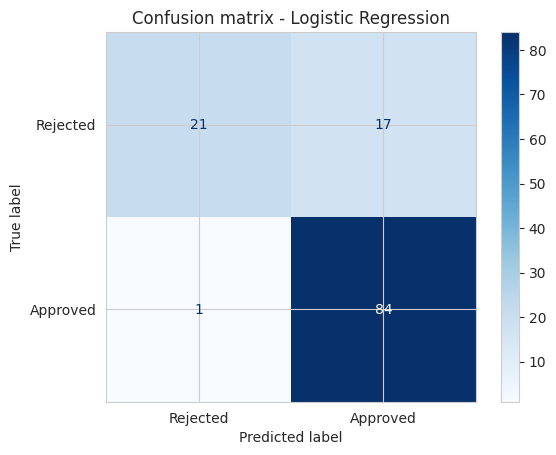

In [40]:
best_name = res_df.loc[0, "Model"]
best_gs, best_pred = fitted[best_name]
print(f"Best model: {best_name}  |  Test accuracy: {res_df.loc[0, 'Test Accuracy']:.2f}%\n")
print(classification_report(y_test, best_pred, target_names=["Rejected", "Approved"]))
 
ConfusionMatrixDisplay(confusion_matrix(y_test, best_pred),
                       display_labels=["Rejected", "Approved"]).plot(cmap="Blues")
plt.title(f"Confusion matrix - {best_name}")
plt.show()

# 12. Feature importance

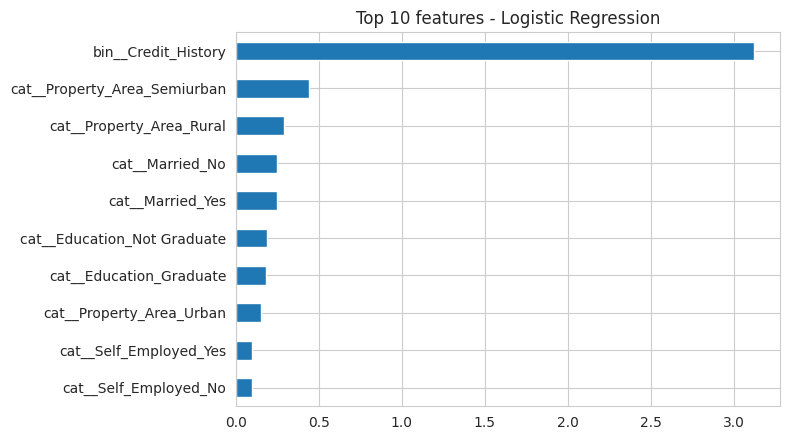

In [41]:
best_pipe = best_gs.best_estimator_
feat_names = best_pipe.named_steps["prep"].get_feature_names_out()
clf = best_pipe.named_steps["clf"]
imp = clf.feature_importances_ if hasattr(clf, "feature_importances_") else np.abs(clf.coef_[0])
imp_s = pd.Series(imp, index=feat_names).sort_values(ascending=False).head(10)
 
plt.figure(figsize=(8, 4.5))
imp_s[::-1].plot(kind="barh")
plt.title(f"Top 10 features - {best_name}")
plt.tight_layout()
plt.show()

# 13. Predict for a new applicant (example)

In [42]:
new_applicant = pd.DataFrame([{
    "Gender": "Male", "Married": "Yes", "Dependents": 1, "Education": "Graduate",
    "Self_Employed": "No", "Loan_Amount_Term": 360, "Credit_History": 1.0,
    "Property_Area": "Urban",
    "TotalIncome_log": np.log1p(6500), "LoanAmount_log": np.log1p(130),
    "EMI": 130 / 360, "Balance_Income": 6500 - (130 / 360) * 1000,
}])
pred = best_gs.predict(new_applicant)[0]
print("Loan decision for example applicant:", "Approved" if pred == 1 else "Rejected")

Loan decision for example applicant: Approved
